# Titanic Encoding and Embedding

**Class 15 – Encoding and Embedding activity**

**Goal.** Represent the categorical Titanic features (`sex`, `pclass`, `embarked`) numerically and judge each representation with *validity, robustness, size and sparsity* checks. We also explore association with `survived` and build a PCA projection of port profiles.

**Scope.**
- Features: `sex`, `pclass`, `embarked` (categorical); `age`, `fare`, `sibsp`, `parch` (only for the port profiles).
- Target: `survived`. It is kept out of every feature transformation and out of the PCA profiles.
- `alive`, identifiers and post-outcome fields are not used.
- The CSV is an imputed fixture of all 891 passengers, so no train/test split is needed. In a predictive workflow we would split first and fit encoders on the training data only.

**Caveat.** Nothing here measures model performance. All results are exploratory.

## 1. Load the data

We load the prepared CSV and check it has the expected 891 rows and 8 columns.

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, spearmanr
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

df = pd.read_csv("Class15_Titanic_Imputed.csv")
print(df.shape)
df.head()

(891, 8)


,sex,pclass,embarked,age,fare,sibsp,parch,survived
0,male,3,S,22.0,7.2500,1.0,0.0,0
1,female,1,C,38.0,71.2833,1.0,0.0,1
2,female,3,S,26.0,7.9250,0.0,0.0,1
3,female,1,S,35.0,53.1000,1.0,0.0,1
4,male,3,S,35.0,8.0500,0.0,0.0,0


## 2. Choose a representation

| Feature | Structure | Candidate | Assumption made by the representation |
|---|---|---|---|
| `sex` | Nominal, 2 categories | One-hot | No order and no distance between categories. |
| `embarked` | Nominal, 3 ports (C, Q, S) | One-hot | No order. Numeric codes like C=0, Q=1, S=2 would invent an order and equal spacing. |
| `pclass` | Ordered, 3 categories | One-hot **vs** ordinal 1, 2, 3 | One-hot: no distance assumed, 3 columns. Ordinal: assumes the 1→2 gap equals the 2→3 gap, 1 column. |

A numeric label is not automatically a meaningful distance. For `pclass` the order is real (1st > 2nd > 3rd), but equal spacing is an assumption, so we inspect both.

### 2.1 One-hot encoding of `sex` and `embarked`

The encoder uses `handle_unknown='ignore'`, so an unseen category becomes an all-zero block instead of raising an error. We check shape, column names and density (share of non-zero entries).

In [10]:
oh_cat = ['sex', 'embarked']

oh_encoded = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_oh = oh_encoded.fit_transform(df[oh_cat])

print("Size:", X_oh.shape)
print("Density:", np.count_nonzero(X_oh) / X_oh.size)
X_oh_df = pd.DataFrame(X_oh, columns=oh_encoded.get_feature_names_out(oh_cat))
X_oh_df.head()

Size: (891, 5)
Density: 0.4


,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0.0,1.0,0.0,0.0,1.0
1,1.0,0.0,1.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


#### Result.
- Matrix shape is (891, 5): `sex_female`, `sex_male`, `embarked_C` `embarked_Q`, `embarked_S`.
- Density is 0.4. This is expected: each row has exactly one `1` per original feature, so 2 non-zeros out of 5 columns = 2/5 = 0.4.
- Learned categories: sex $\to$ {female, male}, embarked $\to$ {C, Q, S}. All categories are covered, and the matrix is small.

### 2.2 Unseen-catagory check

We transform a synthetic row with an unseen port (`NEW_PORT`).

In [13]:
new_row = pd.DataFrame({"sex": ["male"], "embarked": ["NEW_PORT"]})
out = oh_encoded.transform(new_row)
print(pd.DataFrame(out, columns=oh_encoded.get_feature_names_out()))
# Expect sex_male=1 and all embarked_* = 0. The unknown port is ignored without an error.

   sex_female  sex_male  embarked_C  embarked_Q  embarked_S
0         0.0       1.0         0.0         0.0         0.0


**Result.** The row gets `sex_male = 1` and **all three** `embarked_*` columns equal to 0. The known `sex` columns are unchanged and no error is raised, so the encoder handles unseen values safely. The cost is that the model cannot tell an unknown port from "no information". This is a robustness check, not a performance measure.

### 2.3 `pclass`: one-hot vs ordinal
We encode `pclass` with a one-hot encoder (3 columns) and an ordinal encoder with the explicit order 1, 2, 3 (1 column).

In [14]:
pclass_oh = OneHotEncoder(sparse_output=False).fit(df[['pclass']])
pclass_ord = OrdinalEncoder(categories=[[1, 2, 3]]).fit(df[['pclass']])

print("One-hot encoded columns:", pclass_oh.get_feature_names_out(['pclass']))
print("One-hot shape:", pclass_oh.transform(df[['pclass']]).shape)
print("Ordinal encoded shape:", pclass_ord.transform(df[['pclass']]).shape)

One-hot encoded columns: ['pclass_1' 'pclass_2' 'pclass_3']
One-hot shape: (891, 3)
Ordinal encoded shape: (891, 1)


**Result.** One-hot gives **3 columns** (`pclass_1`, `pclass_2`, `pclass_3`), ordinal gives **1 column**. Ordinal is more compact but imposes equal spacing between classes. One-hot costs two more columns and makes no distance assumption.

Survival rates by class (next section) are 0.63, 0.47, 0.24. The steps are 0.16 and 0.23, so the spacing is not exactly equal. Ordinal is defensible for a linear model, but one-hot is safer if we do not want to assume linearity.

## 3. Association with survival

### 3.1 Group sizes and survival rates
We keep the group sizes next to the rates, because a rate from a small group is less reliable.

In [15]:
for col in ["embarked", "pclass"]:
    print(df.groupby(col)["survived"].agg(passenger_count="count", survival_rate="mean").round(2), "\n")

          passenger_count  survival_rate
embarked                                
C                     168           0.55
Q                      77           0.39
S                     646           0.34 

        passenger_count  survival_rate
pclass                                
1                   216           0.63
2                   184           0.47
3                   491           0.24 



**Result.**

| Port | Passengers | Survival rate |
|---|---|---|
| C | 168 | 0.55 |
| Q | 77 | 0.39 |
| S | 646 | 0.34 |

| Class | Passengers | Survival rate |
|---|---|---|
| 1 | 216 | 0.63 |
| 2 | 184 | 0.47 |
| 3 | 491 | 0.24 |

Survival differs across both groupings. Port Q is the smallest group (77), so its rate is the least precise. Port and class are probably related (see the PCA section: C has a much lower mean class number), so the port differences may partly reflect class composition.

### 3.2 Chi-squared and Spearman
- **Chi-squared** (`embarked` vs `survived`): tests whether the observed counts differ from independence. The p-value says *whether* they differ, not *how strongly*.
- **Spearman** (`fare` vs `survived`): rank correlation, giving direction and strength of a monotonic association. `survived` is coded 0/1.
- We do **not** compute Pearson on arbitrary port codes (C=0, Q=1, S=2).

In [16]:
chi2, p, dof, _ = chi2_contingency(pd.crosstab(df['embarked'], df['survived']))
print(f"chi2_contingency: chi2={chi2:.4f}, p-value={p:.4f}, dof={dof}")

rho, p = spearmanr(df['fare'], df['survived'])
print(f"Spearmanr fare~survived: rho={rho:.4f}, p-value={p:.4f}")

chi2_contingency: chi2=25.9645, p-value=0.0000, dof=2
Spearmanr fare~survived: rho=0.3237, p-value=0.0000


**Result.**
- Chi-squared: χ² = 25.96, dof = 2, p < 0.0001. The survival distribution differs across ports, so we reject independence.
- Spearman fare~survived: ρ = 0.32, p < 0.0001. Higher fares are moderately associated with higher survival.

**Interpretation.** These are exploratory associations on 891 passengers. They do not establish causality, and they do not show that the feature or its encoding improves held-out predictions. A p-value this small also reflects the sample size, so it is not a measure of effect size.

### 3.3 Association heatmaps
Two heatmaps from all rows. They are on **different scales** (Spearman ρ vs chi-squared p-values), so colours must not be compared across them.

**Spearman heatmap** (`age`, `fare`, `sibsp`, `parch`, `survived`): valid for numeric/ordinal variables. The diagonal is 1 by definition.

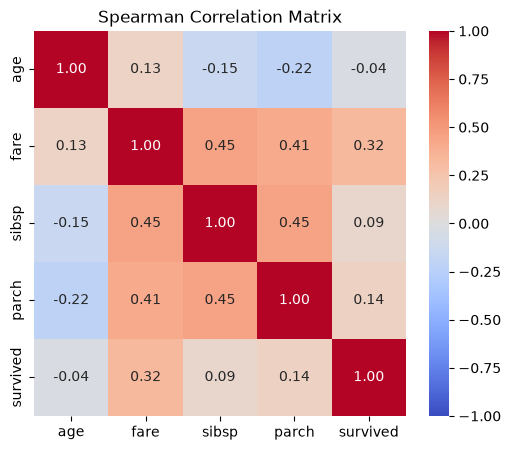

In [17]:
num_cols = ['age', 'fare', 'sibsp', 'parch', 'survived']
corr = df[num_cols].corr(method="spearman")
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Spearman Correlation Matrix")
plt.show()

**Reading the Spearman heatmap.** The `fare`–`survived` cell matches the ρ = 0.32 computed above. Look at the other cells for the direction and size of each pair. Values near 0 mean no monotonic relation. `sibsp` and `parch` are expected to be positively related to each other, since both count family members.

**Chi-squared heatmap** (`sex`, `pclass`, `embarked`, `survived`): chi-squared suits categorical pairs. Cells show p-values, so **darker/smaller means stronger evidence against independence**, not a stronger association. The matrix is symmetric, so only the lower triangle is shown (upper triangle and diagonal masked).

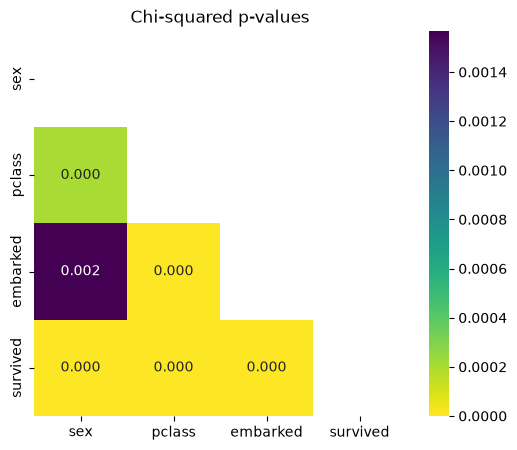

In [19]:
cat_cols = ['sex', 'pclass', 'embarked', 'survived']
pm = pd.DataFrame(np.nan, index=cat_cols, columns=cat_cols)
for a in cat_cols:
    for b in cat_cols:
        if a != b:
            pm.loc[a, b] = chi2_contingency(pd.crosstab(df[a], df[b]))[1]

mask = np.triu(np.ones_like(pm, dtype=bool))
plt.figure(figsize=(6, 5))
sns.heatmap(pm.astype(float), mask=mask, annot=True, fmt='.3f', cmap='viridis_r')
plt.title('Chi-squared p-values')
plt.show()

**Reading the chi-squared heatmap.** The `embarked`–`survived` cell is consistent with the test above (p < 0.001). Compare the `sex`–`survived` and `pclass`–`survived` cells against it. Small p-values mean the variables are not independent. They do not tell us which one helps a model more, and they do not say anything about causes. Because `pclass` and `embarked` may be related to each other, associations with `survived` can overlap.

## 4. PCA projection of port profiles

### 4.1 Profile construction
We build:
- `log_fare = log1p(fare)`, to reduce the skew of fare;
- `family_size = sibsp + parch + 1`;
- `female`, a 0/1 indicator.

For each port the profile is: mean age, mean log fare, mean class, mean family size and female share. **`survived` is excluded.**

In [21]:
d = df.copy()
d['log_fare'] = np.log1p(d['fare'])
d['family_size'] = d['sibsp'] + d['parch'] + 1
d['female'] = (d['sex'] == 'female').astype(int)
d['pclass'] = d['pclass'].astype(int)

# Profile per port. survived is deliberately excluded
prof = d.groupby('embarked').agg(
    mean_age=('age', 'mean'),
    mean_log_fare=('log_fare', 'mean'),
    mean_pclass=('pclass', 'mean'),
    mean_family=('family_size', 'mean'),
    female_share=('female', 'mean'),
)
print(prof.round(3))

          mean_age  mean_log_fare  mean_pclass  mean_family  female_share
embarked                                                                 
C           30.178          3.489        1.887        1.750         0.435
Q           28.032          2.457        2.909        1.597         0.468
S           29.308          2.885        2.347        1.981         0.317


**Result.** (C) has the highest mean log fare (3.49) and the lowest mean class number (1.89), meaning wealthier passengers. (Q) is the opposite: lowest log fare (2.46) and highest mean class number (2.91). (S) is in between, with the largest families (1.98) and the lowest female share (0.32).

### 4.2 Standardise and fit PCA
The profile columns use different scales (years, log-currency, share), so we standardise them. Then we fit a 2-component PCA on the **three** port profiles and plot them, with arrows showing the correlation of each original profile variable with PC1 and PC2.

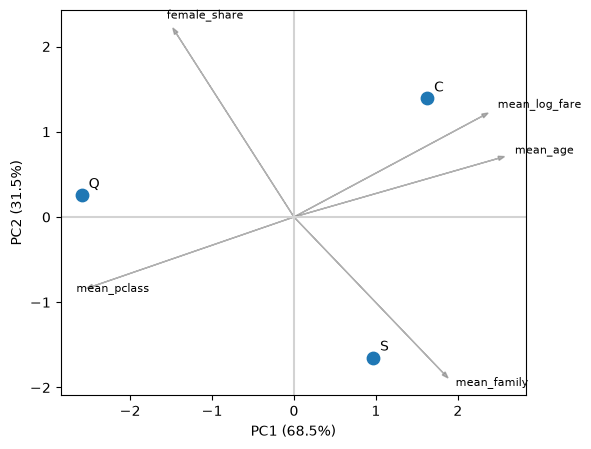

0.9999999999999999                 PC1   PC2
mean_age       0.96  0.27
mean_log_fare  0.89  0.46
mean_pclass   -0.95 -0.31
mean_family    0.71 -0.71
female_share  -0.55  0.83


In [23]:
Z = StandardScaler().fit_transform(prof)
pca = PCA(n_components=2).fit(Z)
S = pca.transform(Z)
ev = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(S[:, 0], S[:, 1], s=80)
for (x, y), port in zip(S, prof.index):
    ax.annotate(port, (x,y), xytext=(5, 5), textcoords='offset points')

# Arrows: correllation of eac profile variable with PC1 and PC2
load = np.array([[np.corrcoef(Z[:, j], S[:, k])[0, 1] for k in range(2)] for j in range(Z.shape[1])])
scale = np.abs(S).max()
for name, (cx, cy) in zip(prof.columns, load):
    ax.arrow(0, 0, cx * scale, cy * scale, color='gray', alpha=.6, head_width=.05)
    ax.text(cx * scale * 1.08, cy * scale * 1.08, name, fontsize=8)
ax.set_xlabel(f"PC1 ({ev[0]:.1%})")
ax.set_ylabel(f"PC2 ({ev[1]:.1%})")
ax.axhline(0, c="lightgray"); ax.axvline(0, c="lightgray")
plt.show()
print(ev.sum(), pd.DataFrame(load, index=prof.columns, columns=["PC1", "PC2"]).round(2))

**Result.**
- PC1 explains about **68.5%** and PC2 about **31.5%** of the variance. They sum to 100%.
- PC1 correlates strongly with `mean_age` (+0.96), `mean_log_fare` (+0.89) and `mean_pclass` (−0.95). It works as a "wealth/status" axis: ports on the right have higher fares and lower class numbers (C), ports on the left the reverse (Q).
- PC2 is driven by `female_share` (+0.83) and `mean_family` (−0.71). It separates ports by gender mix and family size (S has bigger families and fewer women).

**Limitations.**
- With only 3 points, centred data has at most 2 independent dimensions, so two components explain 100% **by construction**. The 100% is not evidence of a good fit.
- The plot is an **exploratory visualisation of aggregate profiles**. It is not a supervised embedding, it does not use `survived`, and it does not show the coordinates would improve a classifier.
- Applying PCA directly to the three one-hot port columns would not be useful compression for the same reason.

## 5. What the evidence supports

**Encoding decision table**

| Feature | Decision | Why |
|---|---|---|
| `sex` | One-hot (2 columns) | Nominal, no order. |
| `embarked` | One-hot (3 columns) | Nominal. Ordinal codes would add a false order. |
| `pclass` | One-hot or ordinal | Real order, but equal spacing is an assumption. Ordinal saves 2 columns. |

**1. Supported claim.** The representation is suitable for this exercise because all categories are covered (sex 2, embarked 3, pclass 3), the unseen port `NEW_PORT` is ignored safely, with all `embarked_*` columns at 0 and no error, and the output is small and clean (891×5, density 0.4). The port-profile PCA also shows interpretable differences among ports: C is wealthier, Q poorer, and S has larger families.

**2. Claim that must wait.** We cannot yet claim that it improves the model, because chi-squared and Spearman only show exploratory association with `survived` on these 891 rows.